# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [10]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
scaler = StandardScaler()

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/home/Xsemka/.conda/envs/ai/lib/python3.12/site-packages/IPython/core/magics/pylab.py:166: UserWarning: pylab import has clobbered these variables: ['figure', 'axis']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [11]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [12]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
from sklearn.datasets import make_regression
import numpy as np

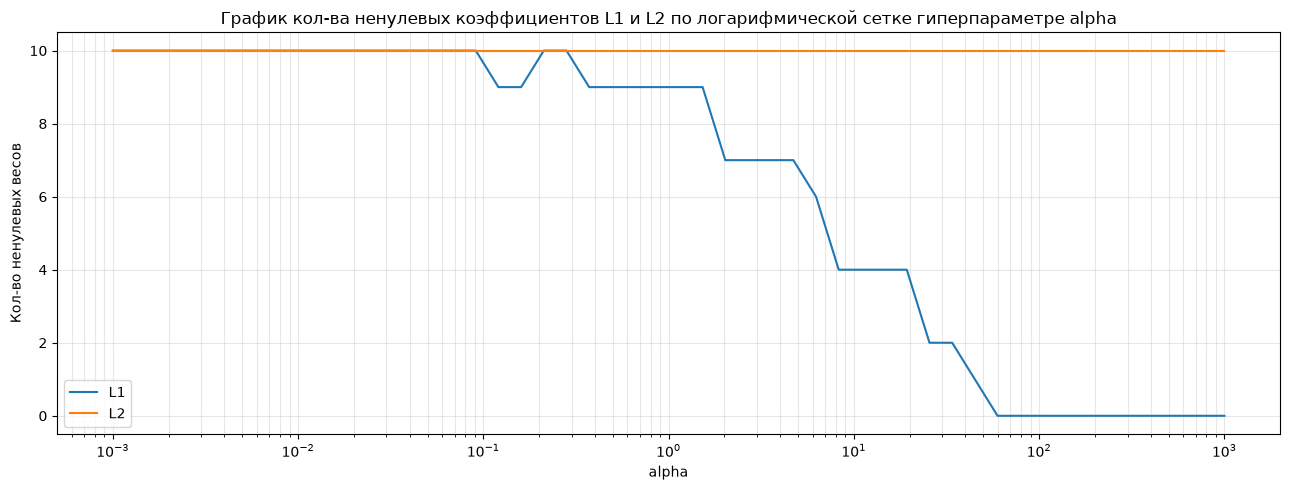

In [13]:
x_train = scaler.fit_transform(X_train)
x_test = scaler.transform(X_test)

def count_log_thr(x, threshold):
    return sum([1 for xi in x if abs(xi) > 10**threshold])


l1_coefs = []
l2_coefs = []

for alpha in np.logspace(-3, 3):
    l1 = Lasso(alpha=alpha).fit(x_train, y_train)
    l1_coefs.append(count_log_thr(l1.coef_, -3))

    l2 = Ridge(alpha=alpha).fit(x_train, y_train)
    l2_coefs.append(count_log_thr(l2.coef_, -3))

figure, axis = plt.subplots(1, 1, figsize=(13, 5))

axis.plot(np.logspace(-3, 3), l1_coefs, label="L1")
axis.plot(np.logspace(-3, 3), l2_coefs, label="L2")

axis.set_xscale('log') 

axis.set_title("Грaфик кол-ва ненулевых коэффициентов L1 и L2 по логарифмической сетке гиперпараметре alpha")
axis.set_xlabel("alpha")
axis.set_ylabel("Кол-во ненулевых весов")
axis.grid(True, alpha=0.3, which="both")
axis.legend()

figure.tight_layout()
plt.show()




Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [14]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error, root_mean_squared_log_error, r2_score, mean_squared_error

In [15]:
l2 = Ridge(alpha=0.5).fit(x_train, y_train)

l2_pred = l2.predict(x_test)

rmse_l2 = root_mean_squared_log_error(y_test, l2_pred)
mae_l2 = mean_absolute_error(y_test, l2_pred)
r2_l2 = r2_score(y_test, l2_pred)

print(f"rmse_l2 {rmse_l2} \n mae_l2 {mae_l2} \n r2_l2 {r2_l2}")

rmse_l2 0.44950606724484105 
 mae_l2 47.15067364066685 
 r2_l2 0.4126266042635611


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

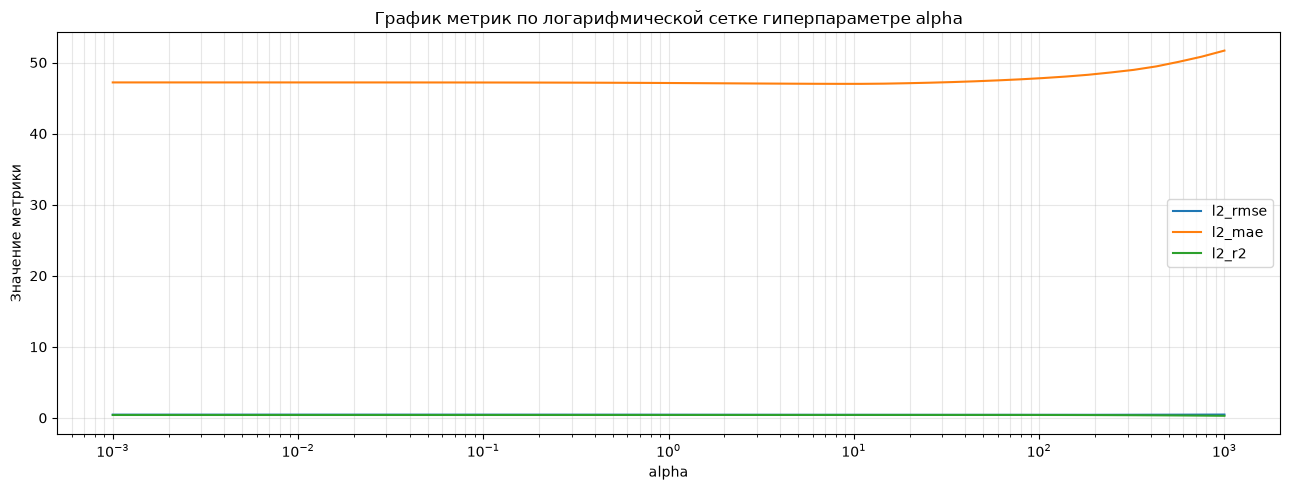

In [16]:
l2_rmse = []
l2_mae = []
l2_r2 = []


for alpha in np.logspace(-3, 3):
    l2 = Ridge(alpha=alpha).fit(x_train, y_train)
    l2_pred = l2.predict(x_test)

    rmse_l2 = root_mean_squared_log_error(y_test, l2_pred)
    mae_l2 = mean_absolute_error(y_test, l2_pred)
    r2_l2 = r2_score(y_test, l2_pred)

    l2_rmse.append(rmse_l2)
    l2_mae.append(mae_l2)
    l2_r2.append(r2_l2)
    

figure, axis = plt.subplots(1, 1, figsize=(13, 5))

axis.plot(np.logspace(-3, 3), l2_rmse, label="l2_rmse")
axis.plot(np.logspace(-3, 3), l2_mae, label="l2_mae")
axis.plot(np.logspace(-3, 3), l2_r2, label="l2_r2")

axis.set_xscale('log') 

axis.set_title("Грaфик метрик по логарифмической сетке гиперпараметре alpha")
axis.set_xlabel("alpha")
axis.set_ylabel("Значение метрики")
axis.grid(True, alpha=0.3, which="both")
axis.legend()

figure.tight_layout()
plt.show()

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

In [17]:
# code here

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [18]:
# code here

__Задание 3.__ Отчёт

**(2 балла)**

In [19]:
# code here